# Notebook 07 — Events Timeline

## Purpose

Place the 19 source posts and the five inventoried institutional communications on one timeline. The publication date comes from the researcher-verified register. `collection_date` is not used as a publication date.

## Linkage rule

A shared topic or a nearby date does not establish that an institution responded to a post or to a comment. This notebook uses four classes:

- `directly linked` — the register states that a communication answers a specific post or comment
- `thematically related` — the register states a topic similarity and does not establish a response
- `temporally associated` — the register states a date alignment and does not establish a response
- `unlinked/unresolved` — no response relationship is established

No post is classed as `directly linked`. The class below is copied from the wording already stored in `linkage_note`.

POST_17 remains a likely topic-level description of NIRA card issuance through the Somali Embassy in Uganda. The original Facebook caption was not recovered. POST_18 remains a probable Eid al-Fitr greeting inferred from the date and from comments. Its original caption was not recovered. Neither description is a government response.


## 1. Load the post crosswalk and the response inventory

Use publication dates from the register. Do not use collection dates as publication dates.


In [1]:
from pathlib import Path
import json
import sys

import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent, Path(r"D:\NIRA_CASE_STUDY")]
ROOT = None
for candidate in candidates:
    if (candidate / "NIRA_Facebook_Datasets_5292.csv").exists():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    raise FileNotFoundError("Project root not found.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from config.project_config import EXPECTED_N_POSTS, EXPECTED_RAW_N

RUN_IN = ROOT / "outputs" / "01_data_preparation" / "20261018_content_review"
RUN_ID = "20261019_events"
OUT = ROOT / "outputs" / "07_events_timeline" / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)

posts = pd.read_csv(RUN_IN / "post_url_crosswalk.csv")
responses = pd.read_csv(RUN_IN / "response_register_as_read.csv")
raw = pd.read_csv(RUN_IN / "raw_corpus_working.csv", usecols=["record_key", "post_id", "publication_date_register", "collection_date_parsed"])
if len(posts) != EXPECTED_N_POSTS:
    raise AssertionError(f"Expected {EXPECTED_N_POSTS} posts, found {len(posts)}.")
if len(raw) != EXPECTED_RAW_N:
    raise AssertionError(f"Expected {EXPECTED_RAW_N} comments, found {len(raw)}.")
if posts["post_url_stripped"].nunique() != EXPECTED_N_POSTS:
    raise AssertionError("Post URLs are not one row per source post.")
print(f"Posts: {len(posts)}")
print(f"Inventoried communications: {len(responses)}")
print(f"Output directory: {OUT}")


Posts: 19
Inventoried communications: 5
Output directory: D:\NIRA_CASE_STUDY\outputs\07_events_timeline\20261019_events


### Interpretation

Nineteen posts and five inventoried communications are loaded. The post URLs are one row per source post and cover the full comment file. The response rows remain inventory records.


## 2. Classify each post's relationship to the response inventory

Copy the class supported by the register wording. Do not add a response the note does not name.


In [2]:
# Classes follow the register wording. They do not add a response the note does not name.
LINKAGE = {
    "POST_01": ("thematically related", "RESP_001"),
    "POST_02": ("unlinked/unresolved", ""),
    "POST_03": ("thematically related", ""),
    "POST_04": ("thematically related", "RESP_001; RESP_002"),
    "POST_05": ("unlinked/unresolved", ""),
    "POST_06": ("unlinked/unresolved", ""),
    "POST_07": ("unlinked/unresolved", ""),
    "POST_08": ("unlinked/unresolved", ""),
    "POST_09": ("temporally associated", "RESP_001"),
    "POST_10": ("unlinked/unresolved", ""),
    "POST_11": ("unlinked/unresolved", ""),
    "POST_12": ("thematically related", ""),
    "POST_13": ("unlinked/unresolved", ""),
    "POST_14": ("unlinked/unresolved", ""),
    "POST_15": ("unlinked/unresolved", ""),
    "POST_16": ("unlinked/unresolved", ""),
    "POST_17": ("unlinked/unresolved", ""),
    "POST_18": ("unlinked/unresolved", ""),
    "POST_19": ("unlinked/unresolved", ""),
}
missing = set(posts["post_id"]) - set(LINKAGE)
if missing:
    raise AssertionError(f"Linkage class missing for {sorted(missing)}.")

posts = posts.copy()
posts["linkage_class"] = posts["post_id"].map(lambda post_id: LINKAGE[post_id][0])
posts["comparison_response_ids"] = posts["post_id"].map(lambda post_id: LINKAGE[post_id][1])
posts["publication_date"] = pd.to_datetime(posts["publication_date"])
posts = posts.sort_values(["publication_date", "post_id"]).reset_index(drop=True)

if (posts["linkage_class"] == "directly linked").any():
    raise AssertionError("A directly linked class was assigned without register support.")

content_note = {
    "POST_17": "Likely topic-level description of NIRA national ID issuance through the Somali Embassy in Uganda. The original Facebook caption was not recovered.",
    "POST_18": "Probable Eid al-Fitr greeting inferred from comments and from the 2026-03-19 publication date. The original Facebook caption was not recovered.",
}
posts["content_qualifier"] = posts["post_id"].map(lambda post_id: content_note.get(post_id, ""))

timeline = posts[[
    "post_id",
    "publication_date",
    "account_name",
    "n_comments",
    "policy_topic",
    "linkage_class",
    "comparison_response_ids",
    "linkage_note",
    "content_evidence_status",
    "content_qualifier",
    "working_content_description",
]].copy()
timeline["publication_date"] = timeline["publication_date"].dt.strftime("%Y-%m-%d")
timeline.to_csv(OUT / "post_timeline.csv", index=False)

responses = responses.copy()
responses["evidence_use"] = "Listed in the response inventory. This notebook does not re-fetch the page and does not treat the row as a confirmed response to a Facebook post."
responses.to_csv(OUT / "response_inventory_timeline.csv", index=False)

class_counts = timeline["linkage_class"].value_counts().rename_axis("linkage_class").reset_index(name="n_posts")
class_counts.to_csv(OUT / "linkage_class_counts.csv", index=False)

year_counts = (
    raw.assign(publication_year=pd.to_datetime(raw["publication_date_register"]).dt.year)
    .groupby("publication_year")
    .size()
    .rename("n_comments")
    .reset_index()
)
year_counts.to_csv(OUT / "comments_by_publication_year.csv", index=False)

summary = {
    "n_posts": int(len(timeline)),
    "n_comments": int(len(raw)),
    "directly_linked_posts": int((timeline["linkage_class"] == "directly linked").sum()),
    "thematically_related_posts": int((timeline["linkage_class"] == "thematically related").sum()),
    "temporally_associated_posts": int((timeline["linkage_class"] == "temporally associated").sum()),
    "unlinked_posts": int((timeline["linkage_class"] == "unlinked/unresolved").sum()),
    "named_comparisons": {
        "POST_01": "RESP_001, thematically related; causality not established in the register",
        "POST_04": "RESP_001 and RESP_002, thematically related; no direct response established",
        "POST_09": "RESP_001, same registered date 2025-11-03; temporal association is not causality",
    },
    "decision": "No inventoried communication is classed as a direct response to a source post or to a comment. Shared topic and nearby dates remain comparisons.",
}
(OUT / "events_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(timeline[["post_id", "publication_date", "n_comments", "linkage_class", "comparison_response_ids"]].to_string(index=False))
print(json.dumps(summary, indent=2))


post_id publication_date  n_comments         linkage_class comparison_response_ids
POST_02       2023-09-16         660   unlinked/unresolved                        
POST_16       2023-09-16          92   unlinked/unresolved                        
POST_05       2023-10-02         320   unlinked/unresolved                        
POST_19       2024-01-30          52   unlinked/unresolved                        
POST_14       2025-09-18          97   unlinked/unresolved                        
POST_12       2025-09-26         160  thematically related                        
POST_03       2025-10-02         642  thematically related                        
POST_10       2025-10-18         200   unlinked/unresolved                        
POST_01       2025-10-27        1013  thematically related                RESP_001
POST_09       2025-11-03         212 temporally associated                RESP_001
POST_04       2025-11-04         505  thematically related      RESP_001; RESP_002
POST

### Interpretation

No post is classed as directly linked. Four posts are thematically related, one is temporally associated, and 14 are unlinked or unresolved. POST_01 shares a topic with RESP_001. POST_09 shares the date 2025-11-03 with RESP_001. POST_04 is thematically related to RESP_001 and RESP_002. Shared topic and a nearby date remain comparisons.


## Reading the timeline

The five communications stay in the inventory with their original evidence status. POST_09 shares the registered date of RESP_001, 2025-11-03. That alignment is temporal. POST_01 and POST_04 are topic comparisons with named inventory rows. The register text already says those comparisons do not establish causality, a direct response, or the truth of an allegation.

Comment volume on a date is the number of collected comments under that source post. It is not a measure of how many people the post reached, and it is not evidence that a later communication answered those comments.


## Pre-event and post-event

The event used for this split is RESP_001, dated 2025-11-03: the SONNA report that the NIRA Director General addressed night-queue concerns. A post is pre-event when its publication date is before that day, event-day when the dates are equal, and post-event when the publication date is later. The split uses `publication_date_register`. It does not use `collection_date`.

The split describes timing. It does not show that RESP_001 caused a change in the comments.


In [3]:
EVENT_ID = "RESP_001"
EVENT_DATE = pd.Timestamp("2025-11-03")
comments = raw[["record_key", "post_id", "publication_date_register"]].copy()
comments["publication_date"] = pd.to_datetime(comments["publication_date_register"])
comments["event_period"] = comments["publication_date"].map(
    lambda value: "pre_event" if value < EVENT_DATE else ("event_day" if value == EVENT_DATE else "post_event")
)
comments["event_id"] = EVENT_ID
comments["event_date"] = "2025-11-03"
comments["date_basis"] = "publication_date_register"
if len(comments) != EXPECTED_RAW_N:
    raise AssertionError("The event split lost comments.")
if comments["event_period"].isna().any():
    raise AssertionError("A comment has no event period.")

predictions = pd.read_csv(ROOT / "outputs" / "06_results_predictions" / "20261019_predictions" / "corpus_predictions.csv")
pred_cols = [column for column in predictions.columns if column.startswith("pred_")]
comments = comments.merge(predictions[["record_key", "is_annotated", *pred_cols]], on="record_key", how="left")
if comments[pred_cols].isna().any().any():
    raise AssertionError("A comment did not receive a prediction.")
comments.to_csv(OUT / "comments_by_event_period.csv", index=False)

post_periods = (
    comments.groupby(["post_id", "publication_date", "event_period"], as_index=False)
    .size()
    .rename(columns={"size": "n_comments"})
)
post_periods["publication_date"] = post_periods["publication_date"].dt.strftime("%Y-%m-%d")
post_periods = post_periods.merge(
    timeline[["post_id", "linkage_class", "comparison_response_ids"]],
    on="post_id",
    how="left",
)
post_periods.to_csv(OUT / "posts_by_event_period.csv", index=False)

summary_rows = []
for period in ("pre_event", "event_day", "post_event"):
    part = comments[comments["event_period"] == period]
    summary_rows.append({
        "event_id": EVENT_ID,
        "event_date": "2025-11-03",
        "event_period": period,
        "n_posts": int(part["post_id"].nunique()),
        "n_comments": int(len(part)),
        "n_annotated": int(part["is_annotated"].astype(bool).sum()),
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "event_period_summary.csv", index=False)
if int(summary["n_comments"].sum()) != EXPECTED_RAW_N:
    raise AssertionError("Event periods do not cover every comment.")

share_rows = []
for period in ("pre_event", "event_day", "post_event"):
    part = comments[comments["event_period"] == period]
    for column in pred_cols:
        counts = part[column].astype(str).value_counts()
        for label, count in counts.items():
            share_rows.append({
                "event_period": period,
                "task": column.replace("pred_", ""),
                "label": label,
                "n": int(count),
                "denominator": int(len(part)),
                "share": float(count / len(part)),
                "label_source": "refit prediction, not a manual label and not an effect of the event",
            })
pd.DataFrame(share_rows).to_csv(OUT / "predicted_label_shares_by_event_period.csv", index=False)

payload = {
    "event_id": EVENT_ID,
    "event_date": "2025-11-03",
    "event_definition": "SONNA report that the NIRA Director General addressed night-queue concerns.",
    "date_basis": "publication_date_register of the source post",
    "collection_date_used": False,
    "causal_claim": False,
    "directly_linked_posts": 0,
    "periods": summary_rows,
}
(OUT / "event_period_definition.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print(summary.to_string(index=False))
print(json.dumps(payload, indent=2))


event_id event_date event_period  n_posts  n_comments  n_annotated
RESP_001 2025-11-03    pre_event        9        3236          734
RESP_001 2025-11-03    event_day        1         212           48
RESP_001 2025-11-03   post_event        9        1844          417
{
  "event_id": "RESP_001",
  "event_date": "2025-11-03",
  "event_definition": "SONNA report that the NIRA Director General addressed night-queue concerns.",
  "date_basis": "publication_date_register of the source post",
  "collection_date_used": false,
  "causal_claim": false,
  "directly_linked_posts": 0,
  "periods": [
    {
      "event_id": "RESP_001",
      "event_date": "2025-11-03",
      "event_period": "pre_event",
      "n_posts": 9,
      "n_comments": 3236,
      "n_annotated": 734
    },
    {
      "event_id": "RESP_001",
      "event_date": "2025-11-03",
      "event_period": "event_day",
      "n_posts": 1,
      "n_comments": 212,
      "n_annotated": 48
    },
    {
      "event_id": "RESP_001",
      

### Interpretation

RESP_001 on 2025-11-03 is the event used for the dashboard split. Posts published earlier contribute 3,236 comments, POST_09 on the event day contributes 212, and later posts contribute 1,844. The annotated counts in those periods are 734, 48, and 417. Predicted label shares are saved beside the split. They describe model output in each period. They do not measure an effect of the SONNA report.


## 4. Draw the feedback-loop sequence

Use the saved post timeline and the saved response inventory. Draw only the items the register names around RESP_001. Arrow labels copy the linkage class. An arrow does not claim that one item caused the next.


D:\NIRA_CASE_STUDY\outputs\07_events_timeline\20261019_events\figures\feedback_loop_sequence.png


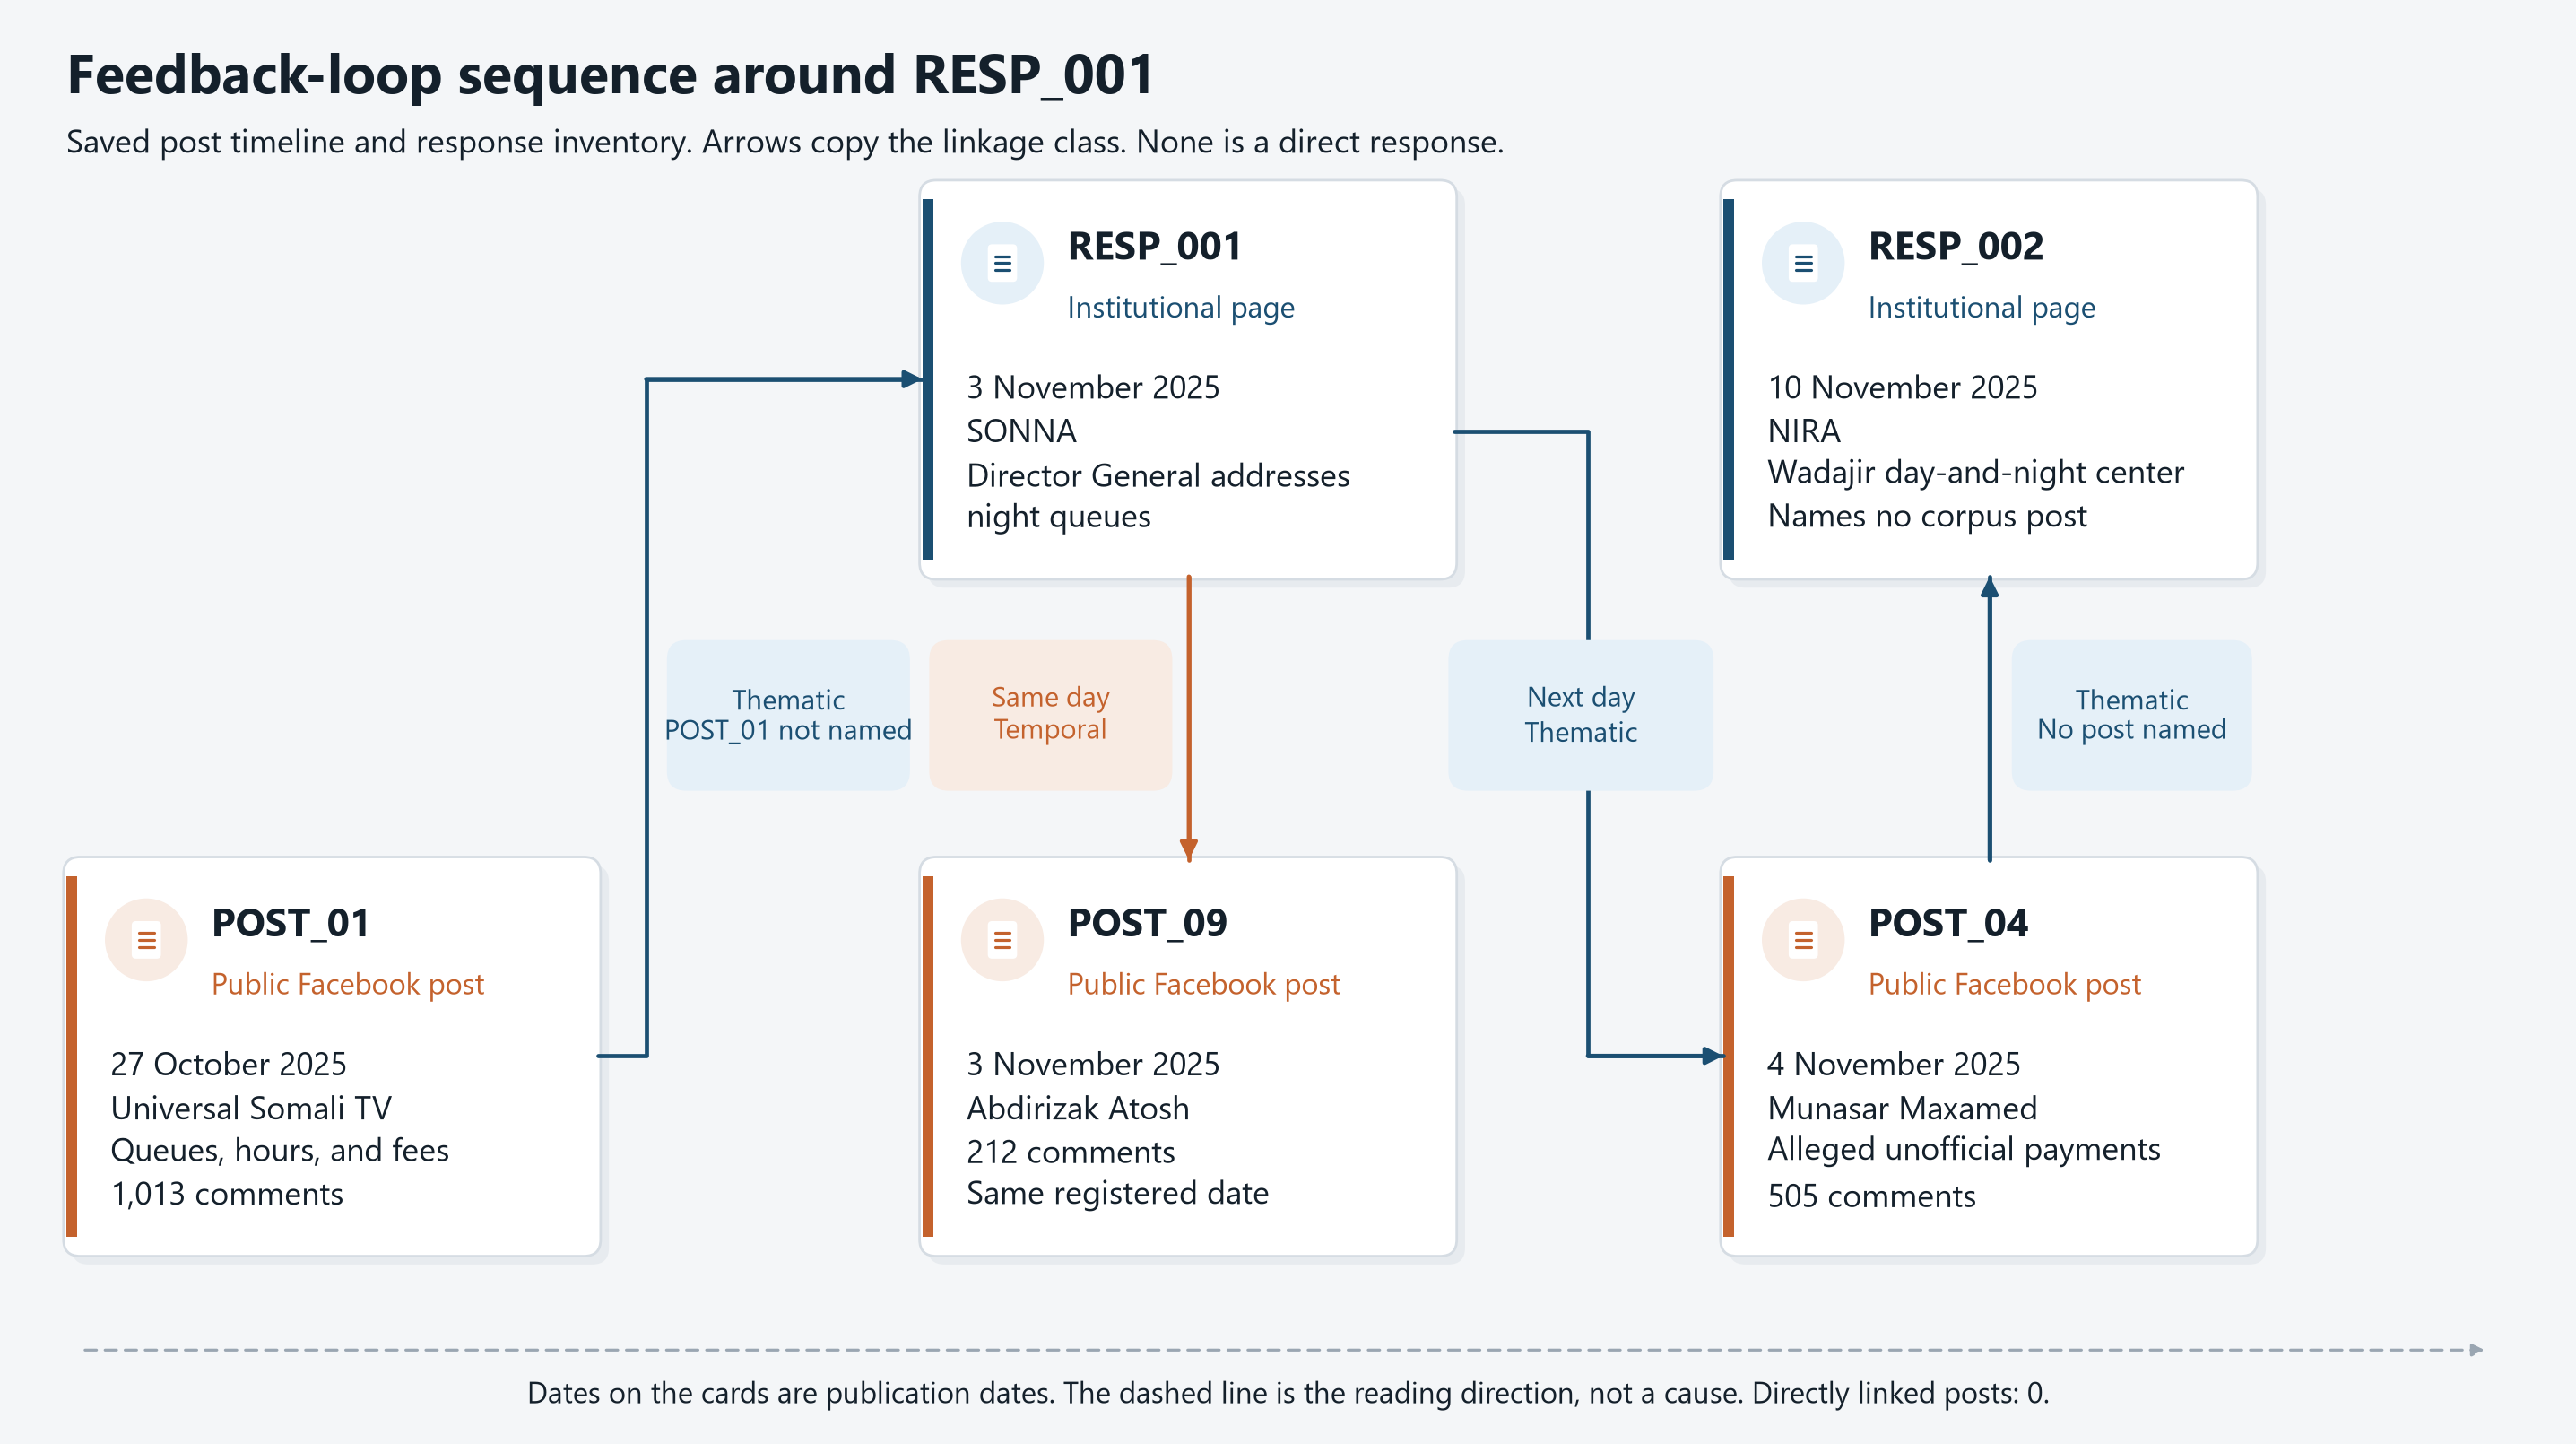

In [4]:
"""Draw a spaced feedback-loop figure from the saved event tables."""

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Circle, Polygon

candidates = [Path.cwd(), Path.cwd().parent, Path(r"D:\NIRA_CASE_STUDY")]
ROOT = None
for candidate in candidates:
    if (candidate / "NIRA_Facebook_Datasets_5292.csv").exists():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    raise FileNotFoundError("Project root not found.")
EVENTS = ROOT / "outputs" / "07_events_timeline" / "20261019_events"
FIG_DIR = EVENTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT = FIG_DIR / "feedback_loop_sequence.png"

posts = pd.read_csv(EVENTS / "post_timeline.csv")
responses = pd.read_csv(EVENTS / "response_inventory_timeline.csv")


def one_post(post_id):
    row = posts.loc[posts["post_id"] == post_id]
    if len(row) != 1:
        raise ValueError(f"{post_id} rows: {len(row)}")
    return row.iloc[0]


def one_response(response_id):
    row = responses.loc[responses["response_id"] == response_id]
    if len(row) != 1:
        raise ValueError(f"{response_id} rows: {len(row)}")
    return row.iloc[0]


post_01 = one_post("POST_01")
post_09 = one_post("POST_09")
post_04 = one_post("POST_04")
resp_001 = one_response("RESP_001")
resp_002 = one_response("RESP_002")

assert post_01["linkage_class"] == "thematically related"
assert post_01["comparison_response_ids"] == "RESP_001"
assert int(post_01["n_comments"]) == 1013
assert post_09["linkage_class"] == "temporally associated"
assert post_09["comparison_response_ids"] == "RESP_001"
assert post_09["publication_date"] == resp_001["date"] == "2025-11-03"
assert int(post_09["n_comments"]) == 212
assert post_04["linkage_class"] == "thematically related"
assert post_04["comparison_response_ids"] == "RESP_001; RESP_002"
assert int(post_04["n_comments"]) == 505
assert resp_002["date"] == "2025-11-10"
assert int((posts["linkage_class"] == "directly linked").sum()) == 0

INK = "#14202B"
MUTED = "#5C6B7A"
PUBLIC = "#C4622D"
PUBLIC_SOFT = "#F8EBE3"
INST = "#1B4F72"
INST_SOFT = "#E5F0F8"
LINE = "#D5DCE3"
PAGE = "#F4F6F8"

plt.rcParams["font.family"] = "Segoe UI"
fig, ax = plt.subplots(figsize=(18.4, 10.2))
ax.set_xlim(0, 18.4)
ax.set_ylim(0, 10.2)
ax.set_aspect("equal")
ax.axis("off")
fig.patch.set_facecolor(PAGE)
ax.set_facecolor(PAGE)


def card(x, y, w, h, accent, icon, kind, title, lines):
    ax.add_patch(
        FancyBboxPatch(
            (x + 0.06, y - 0.06),
            w,
            h,
            boxstyle="round,pad=0.02,rounding_size=0.12",
            facecolor="#E7EBEF",
            edgecolor="none",
            zorder=1,
        )
    )
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.02,rounding_size=0.12",
            facecolor="white",
            edgecolor=LINE,
            linewidth=1.0,
            zorder=2,
        )
    )
    ax.add_patch(plt.Rectangle((x, y + 0.12), 0.08, h - 0.24, facecolor=accent, edgecolor="none", zorder=3))
    cx, cy = x + 0.58, y + h - 0.58
    ax.add_patch(Circle((cx, cy), 0.30, facecolor=icon, edgecolor="none", zorder=4))
    if kind == "public":
        ax.add_patch(
            FancyBboxPatch(
                (cx - 0.13, cy - 0.07),
                0.26,
                0.18,
                boxstyle="round,pad=0.008,rounding_size=0.06",
                facecolor="white",
                edgecolor="none",
                zorder=5,
            )
        )
        ax.add_patch(
            Polygon(
                [[cx - 0.07, cy - 0.07], [cx - 0.01, cy - 0.16], [cx + 0.05, cy - 0.07]],
                closed=True,
                facecolor="white",
                edgecolor="none",
                zorder=5,
            )
        )
    else:
        ax.add_patch(
            FancyBboxPatch(
                (cx - 0.10, cy - 0.13),
                0.20,
                0.26,
                boxstyle="round,pad=0.006,rounding_size=0.03",
                facecolor="white",
                edgecolor="none",
                zorder=5,
            )
        )
        for shift in (0.05, 0.0, -0.05):
            ax.plot(
                [cx - 0.055, cx + 0.055],
                [cy + shift, cy + shift],
                color=accent,
                lw=1.15,
                solid_capstyle="round",
                zorder=6,
            )
    ax.text(x + 1.05, y + h - 0.48, title, ha="left", va="center", fontsize=16, fontweight="bold", color=INK, zorder=6)
    ax.text(x + 1.05, y + h - 0.92, kind, ha="left", va="center", fontsize=12, color=accent, zorder=6)
    ax.text(
        x + 0.32,
        y + 0.26,
        "\n".join(lines),
        ha="left",
        va="bottom",
        fontsize=13,
        color=INK,
        linespacing=1.45,
        zorder=6,
    )


def pill(x, y, w, h, text, fg, bg):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.02,rounding_size=0.14",
            facecolor=bg,
            edgecolor="none",
            zorder=5,
        )
    )
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=11, color=fg, linespacing=1.25, zorder=6)


def route(points, color):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=color, lw=1.7, solid_capstyle="round", solid_joinstyle="round", zorder=3)
    ax.add_patch(
        FancyArrowPatch(
            points[-2],
            points[-1],
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=1.7,
            color=color,
            shrinkA=0,
            shrinkB=0,
            zorder=3,
        )
    )


card(
    0.35,
    1.25,
    3.85,
    2.85,
    PUBLIC,
    PUBLIC_SOFT,
    "Public Facebook post",
    "POST_01",
    [
        "27 October 2025",
        str(post_01["account_name"]),
        "Queues, hours, and fees",
        f"{int(post_01['n_comments']):,} comments",
    ],
)
card(
    6.55,
    6.15,
    3.85,
    2.85,
    INST,
    INST_SOFT,
    "Institutional page",
    "RESP_001",
    [
        "3 November 2025",
        "SONNA",
        "Director General addresses",
        "night queues",
    ],
)
card(
    6.55,
    1.25,
    3.85,
    2.85,
    PUBLIC,
    PUBLIC_SOFT,
    "Public Facebook post",
    "POST_09",
    [
        "3 November 2025",
        str(post_09["account_name"]),
        f"{int(post_09['n_comments']):,} comments",
        "Same registered date",
    ],
)
card(
    12.35,
    1.25,
    3.85,
    2.85,
    PUBLIC,
    PUBLIC_SOFT,
    "Public Facebook post",
    "POST_04",
    [
        "4 November 2025",
        str(post_04["account_name"]),
        "Alleged unofficial payments",
        f"{int(post_04['n_comments']):,} comments",
    ],
)
card(
    12.35,
    6.15,
    3.85,
    2.85,
    INST,
    INST_SOFT,
    "Institutional page",
    "RESP_002",
    [
        "10 November 2025",
        "NIRA",
        "Wadajir day-and-night center",
        "Names no corpus post",
    ],
)

route([(4.20, 2.68), (4.55, 2.68), (4.55, 7.58), (6.55, 7.58)], INST)
route([(8.48, 6.15), (8.48, 4.10)], PUBLIC)
route([(10.40, 7.20), (11.37, 7.20), (11.37, 2.68), (12.35, 2.68)], INST)
route([(14.28, 4.10), (14.28, 6.15)], INST)

pill(4.72, 4.62, 1.72, 1.05, "Thematic\nPOST_01 not named", INST, INST_SOFT)
pill(6.62, 4.62, 1.72, 1.05, "Same day\nTemporal", PUBLIC, PUBLIC_SOFT)
pill(10.38, 4.62, 1.88, 1.05, "Next day\nThematic", INST, INST_SOFT)
pill(14.46, 4.62, 1.70, 1.05, "Thematic\nNo post named", INST, INST_SOFT)

ax.annotate(
    "",
    xy=(17.9, 0.55),
    xytext=(0.45, 0.55),
    arrowprops={"arrowstyle": "-|>", "color": "#9AA6B2", "lw": 1.15, "linestyle": (0, (4, 3))},
)
ax.text(
    9.2,
    0.22,
    "Dates on the cards are publication dates. The dashed line is the reading direction, not a cause. Directly linked posts: 0.",
    ha="center",
    va="center",
    fontsize=12,
    color=INK,
)

ax.text(0.35, 9.75, "Feedback-loop sequence around RESP_001", ha="left", va="center", fontsize=22, fontweight="bold", color=INK)
ax.text(
    0.35,
    9.28,
    "Saved post timeline and response inventory. Arrows copy the linkage class. None is a direct response.",
    ha="left",
    va="center",
    fontsize=13,
    color=INK,
)

fig.savefig(OUT, dpi=200, bbox_inches="tight", facecolor=PAGE)
plt.close(fig)
print(OUT)
display(Image(filename=str(OUT)))


### Interpretation

The figure places five recorded items in publication order. POST_01 on 27 October 2025 is a public post about queues, hours, and fees, with 1,013 comments. Its arrow to RESP_001 is thematic: the SONNA page does not name POST_01. RESP_001 and POST_09 share 3 November 2025, so the arrow between them is temporal. POST_04 falls on the next day, 4 November 2025, and carries 505 comments about alleged unofficial payments. That arrow is thematic. POST_04 then points to RESP_002 on 10 November 2025, the Wadajir day-and-night center, and that page names no corpus post. The dashed line is publication order. Directly linked posts remain 0. POST_03 and POST_12 are thematically related in the register, but neither names RESP_001 or RESP_002, so they are not on this figure.
